In [ ]:
#lets write some crazy good code
!pip install segmentation-models-pytorch efficientnet-pytorch albumentations==1.3.0 --quiet

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import cv2, os
import albumentations as A
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
from tqdm import tqdm
from google.colab import drive

drive.mount('/content/drive')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using: cuda


In [ ]:
COLOR_MAP = {
    (0, 0, 0): 0,          # Background
    (255, 0, 124): 1,      # Oil
    (255, 204, 51): 2,     # Others
    (51, 221, 255): 3      # Water
}
CLASS_COLORS = np.array(list(COLOR_MAP.keys()))

def mask_to_class(mask):
    mask_out = np.zeros((mask.shape[0], mask.shape[1]), dtype=np.int64)
    for rgb, idx in COLOR_MAP.items():
        matches = np.all(mask == np.array(rgb), axis=-1)
        mask_out[matches] = idx
    return mask_out

def class_to_color(mask):
    return CLASS_COLORS[mask]

class OilSpillDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir, self.mask_dir = img_dir, mask_dir
        self.images = sorted(os.listdir(img_dir))
        self.masks = sorted(os.listdir(mask_dir))
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = cv2.imread(os.path.join(self.img_dir, self.images[idx]))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(os.path.join(self.mask_dir, self.masks[idx]))
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
        mask = mask_to_class(mask)

        if self.transform:
            augmented = self.transform(image=img, mask=mask)
            img, mask = augmented['image'], augmented['mask']

        img = torch.from_numpy(img.transpose(2,0,1)).float() / 255.0
        mask = torch.from_numpy(mask).long()
        return img, mask


In [ ]:
train_transform = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.HueSaturationValue(p=0.3),
    A.GaussianBlur(p=0.2),
])

val_transform = A.Compose([A.Resize(256, 256)])


In [ ]:

dataset_path = "/content/drive/MyDrive/AI/dataset.zip"
!unzip -q {dataset_path} -d /content/

!ls /content/dataset/train/images | head
!ls /content/dataset/train/masks | head

train_dataset = OilSpillDataset(
    "train/images",
    "train/masks",
    transform=train_transform
)
val_dataset = OilSpillDataset(
    "val/images",
    "val/masks",
    transform=val_transform
)

print("Train size:", len(train_dataset))
print("Val size:", len(val_dataset))


replace /content/label_colors.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
y
ls: cannot access '/content/dataset/train/images': No such file or directory
ls: cannot access '/content/dataset/train/masks': No such file or directory
Train size: 811
Val size: 203


In [ ]:
model = smp.UnetPlusPlus(
    encoder_name="timm-efficientnet-b4",
    encoder_weights="imagenet",
    in_channels=3,
    classes=4
).to(device)

ce_loss = nn.CrossEntropyLoss()
dice_loss = smp.losses.DiceLoss(mode='multiclass')

def loss_fn(pred, target):
    return 0.5 * ce_loss(pred, target) + 0.5 * dice_loss(pred, target)

optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
scaler = torch.cuda.amp.GradScaler()  #


/tmp/ipython-input-2993008609.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()  #


In [ ]:
from torch.utils.data import DataLoader


BATCH_SIZE = 16


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,      # Shuffle training data
    num_workers=2,     # Speeds up loading
    pin_memory=True    # Helps move data to GPU faster
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f"✅ DataLoaders created with batch size {BATCH_SIZE}")

✅ DataLoaders created with batch size 16


In [ ]:
def train_model(num_epochs=30, patience=5):
    best_iou, patience_ctr = 0, 0
    for epoch in range(num_epochs):
        model.train()
        train_loss, train_iou = 0, 0
        for imgs, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Training"):
            imgs, masks = imgs.to(device), masks.to(device)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast():
                preds = model(imgs)
                loss = loss_fn(preds, masks)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item()
            preds_class = torch.argmax(preds, dim=1)
            train_iou += (preds_class == masks).float().mean().item()

        scheduler.step()

        # Validation
        model.eval()
        val_loss, val_iou = 0, 0
        with torch.no_grad():
            for imgs, masks in tqdm(val_loader, desc="Validating"):
                imgs, masks = imgs.to(device), masks.to(device)
                preds = model(imgs)
                loss = loss_fn(preds, masks)
                val_loss += loss.item()
                preds_class = torch.argmax(preds, dim=1)
                val_iou += (preds_class == masks).float().mean().item()

        val_loss /= len(val_loader)
        val_iou /= len(val_loader)

        print(f"Epoch {epoch+1}: Train Loss={train_loss/len(train_loader):.4f}, Val Loss={val_loss:.4f}, Val IoU={val_iou:.4f}")

        if val_iou > best_iou:
            best_iou = val_iou
            patience_ctr = 0
            torch.save(model.state_dict(), "/content/drive/MyDrive/AI/best_unetpp_effb4.pth")
            print("✅ Saved Best Model")
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print("⏹ Early stopping triggered")
                break



In [ ]:
train_model(num_epochs=20, patience=5)


Epoch 1/20 - Training:   0%|          | 0/51 [00:00<?, ?it/s]/tmp/ipython-input-1267546644.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Validating: 100%|██████████| 13/13 [01:03<00:00,  4.92s/it]


Epoch 1: Train Loss=0.8021, Val Loss=0.5631, Val IoU=0.8210
✅ Saved Best Model


Validating: 100%|██████████| 13/13 [01:02<00:00,  4.78s/it]


Epoch 2: Train Loss=0.5289, Val Loss=0.4140, Val IoU=0.8974
✅ Saved Best Model


Validating: 100%|██████████| 13/13 [01:01<00:00,  4.71s/it]


...

Epoch 10: Train Loss=0.2740, Val Loss=0.2392, Val IoU=0.9375


Validating: 100%|██████████| 13/13 [01:04<00:00,  4.97s/it]


Epoch 11: Train Loss=0.2808, Val Loss=0.2375, Val IoU=0.9387


Validating: 100%|██████████| 13/13 [01:02<00:00,  4.84s/it]

Epoch 12: Train Loss=0.2757, Val Loss=0.2399, Val IoU=0.9378
⏹ Early stopping triggered


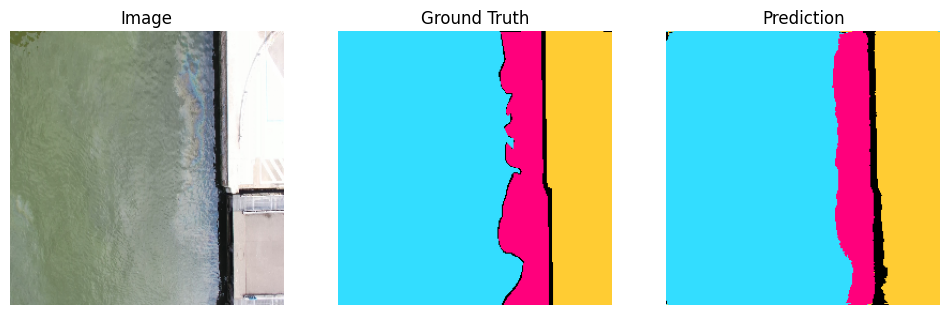

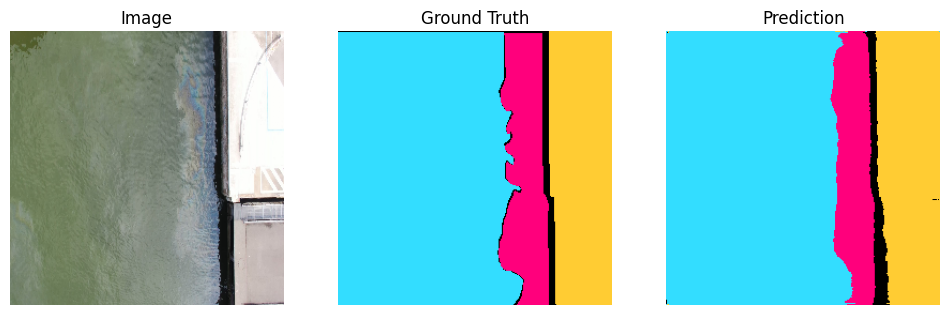

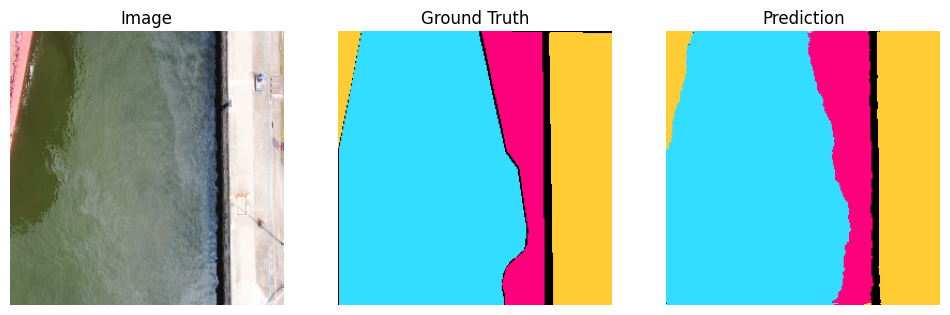

In [ ]:
def show_predictions(dataset, n=3):
    model.eval()
    for i in range(n):
        img, mask = dataset[i]
        img_in = img.unsqueeze(0).to(device)
        with torch.no_grad():
            pred = model(img_in)
            pred_class = torch.argmax(pred, dim=1).cpu().squeeze().numpy()
        plt.figure(figsize=(12,4))
        plt.subplot(1,3,1); plt.imshow(img.permute(1,2,0).numpy()); plt.title("Image"); plt.axis("off")
        plt.subplot(1,3,2); plt.imshow(class_to_color(mask.numpy())); plt.title("Ground Truth"); plt.axis("off")
        plt.subplot(1,3,3); plt.imshow(class_to_color(pred_class)); plt.title("Prediction"); plt.axis("off")
        plt.show()

show_predictions(val_dataset, 3)


In [ ]:
#lets go

model = smp.UnetPlusPlus(
    encoder_name="timm-efficientnet-b4",
    encoder_weights=None,  # we are loading weights, no need for imagenet here
    in_channels=3,
    classes=4
).to(device)

model.load_state_dict(torch.load("/content/drive/MyDrive/AI/best_unetpp_effb4.pth", map_location=device))
model.eval()

print("✅ Best model loaded successfully!")


✅ Best model loaded successfully!


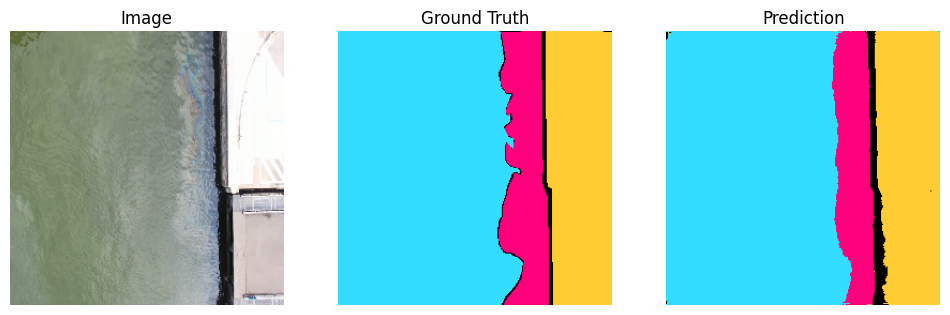

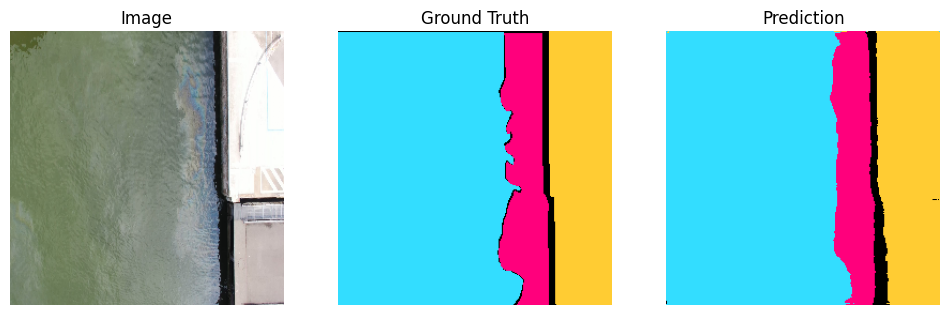

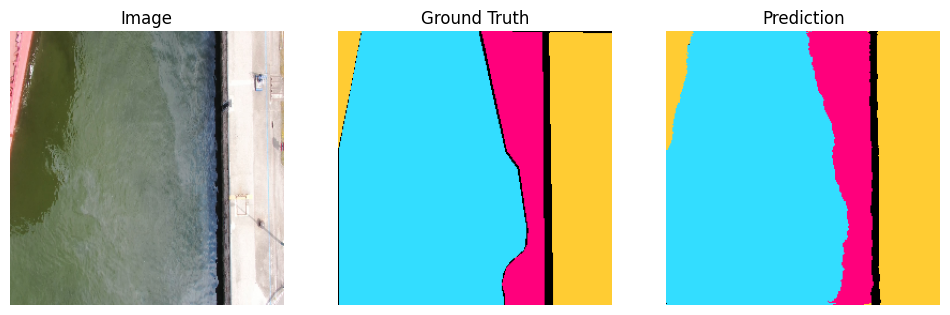

In [ ]:
show_predictions(val_dataset, n=3)


In [ ]:
!pip install transformers --quiet
from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation
import torch.nn.functional as F
from PIL import Image

In [ ]:
CHECKPOINT = "nvidia/segformer-b1-finetuned-ade-512-512"

image_processor = SegformerImageProcessor.from_pretrained(CHECKPOINT)

model_segformer_hf = SegformerForSemanticSegmentation.from_pretrained(
    CHECKPOINT,
    num_labels=4,
    id2label={i: name for i, name in enumerate(CLASS_NAMES)},
    label2id={name: i for i, name in enumerate(CLASS_NAMES)},
    ignore_mismatched_sizes=True
).to(device)

print("Hugging Face SegFormer model and processor loaded.")

/usr/local/lib/python3.12/dist-packages/transformers/image_processing_base.py:417: UserWarning: The following named arguments are not valid for `SegformerImageProcessor.__init__` and were ignored: 'feature_extractor_type', 'reduce_labels'
  image_processor = cls(**image_processor_dict)
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b1-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpoint and torch.Size([4, 256, 1, 1]) in the model instantiated
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([4]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Hugging Face SegFormer model and processor loaded.


In [ ]:
class HFOilSpillDataset(Dataset):
    def __init__(self, img_dir, mask_dir, image_processor):
        self.img_dir, self.mask_dir = img_dir, mask_dir
        self.images = sorted(os.listdir(img_dir))
        self.masks = sorted(os.listdir(mask_dir))
        self.image_processor = image_processor

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.masks[idx])

        img = Image.open(img_path).convert("RGB")

        mask_rgb = cv2.imread(mask_path)
        mask_rgb = cv2.cvtColor(mask_rgb, cv2.COLOR_BGR2RGB)
        mask = mask_to_class(mask_rgb)
        mask = Image.fromarray(mask.astype(np.uint8))

        inputs = self.image_processor(
            images=img,
            segmentation_maps=mask,
            return_tensors="pt"
        )

        return {
            "pixel_values": inputs["pixel_values"].squeeze(),
            "labels": inputs["labels"].squeeze().long()
        }

In [ ]:
hf_train_dataset = HFOilSpillDataset(
    "train/images",
    "train/masks",
    image_processor=image_processor
)

hf_val_dataset = HFOilSpillDataset(
    "val/images",
    "val/masks",
    image_processor=image_processor
)

hf_train_loader = DataLoader(
    hf_train_dataset,
    batch_size=BATCH_SIZE, # from your previous cell
    shuffle=True,
    num_workers=2
)

hf_val_loader = DataLoader(
    hf_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Hugging Face DataLoaders created.")

Hugging Face DataLoaders created.


In [ ]:
def train_model_hf(model_to_train, optimizer, scheduler, save_path, num_epochs=30, patience=5):
    best_val_loss = float('inf')
    patience_ctr = 0
    print(f"--- Starting HF training. Saving best to: {save_path} ---")

    for epoch in range(num_epochs):
        model_to_train.train()
        train_loss = 0

        for batch in tqdm(hf_train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Training"):
            batch = {k: v.to(device) for k, v in batch.items()}

            optimizer.zero_grad()

            outputs = model_to_train(**batch)
            loss = outputs.loss

            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        scheduler.step()

        model_to_train.eval()
        val_loss = 0
        with torch.no_grad():
            for batch in tqdm(hf_val_loader, desc="Validating"):
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model_to_train(**batch)
                val_loss += outputs.loss.item()

        avg_train_loss = train_loss / len(hf_train_loader)
        avg_val_loss = val_loss / len(hf_val_loader)

        print(f"Epoch {epoch+1}: Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}")

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_ctr = 0
            torch.save(model_to_train.state_dict(), save_path)
            print(f"Saved Best Model to {save_path}")
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print("Early stopping triggered")
                break
    print("--- Training complete ---")

In [ ]:
optimizer_hf = optim.AdamW(model_segformer_hf.parameters(), lr=5e-5)
scheduler_hf = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_hf, T_max=10)

HF_SAVE_PATH = "/content/drive/MyDrive/AI/best_hf_segformer_b1.pth"

train_model_hf(
    model_segformer_hf,
    optimizer_hf,
    scheduler_hf,
    HF_SAVE_PATH,
    num_epochs=20,
    patience=2
)

--- Starting HF training. Saving best to: /content/drive/MyDrive/AI/best_hf_segformer_b1.pth ---


Validating: 100%|██████████| 13/13 [01:08<00:00,  5.23s/it]


Epoch 1: Train Loss=0.9267, Val Loss=0.5500
Saved Best Model to /content/drive/MyDrive/AI/best_hf_segformer_b1.pth


Validating: 100%|██████████| 13/13 [01:09<00:00,  5.33s/it]


Epoch 2: Train Loss=0.5198, Val Loss=0.3593
Saved Best Model to /content/drive/MyDrive/AI/best_hf_segformer_b1.pth


...

Epoch 10: Train Loss=0.2350, Val Loss=0.2032
Saved Best Model to /content/drive/MyDrive/AI/best_hf_segformer_b1.pth


Validating: 100%|██████████| 13/13 [01:18<00:00,  6.00s/it]


Epoch 11: Train Loss=0.2296, Val Loss=0.2039


Validating: 100%|██████████| 13/13 [01:08<00:00,  5.24s/it]

Epoch 12: Train Loss=0.2342, Val Loss=0.2032
Early stopping triggered
--- Training complete ---


In [ ]:
def run_full_evaluation_hf(model_to_eval, model_name):
    print(f"--- Running evaluation for {model_name} ---")

    iou_metric = MulticlassJaccardIndex(num_classes=NUM_CLASSES, average=None).to(device)
    miou_metric = MulticlassJaccardIndex(num_classes=NUM_CLASSES, average='macro').to(device)
    cm_metric = MulticlassConfusionMatrix(num_classes=NUM_CLASSES, normalize='true').to(device)

    model_to_eval.eval()
    with torch.no_grad():
        for batch in tqdm(hf_val_loader, desc=f"Evaluating {model_name}"):
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch["labels"]

            outputs = model_to_eval(pixel_values=batch["pixel_values"])
            logits = outputs.logits

            upsampled_logits = F.interpolate(
                logits,
                size=labels.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            preds_class = torch.argmax(upsampled_logits, dim=1)

            iou_metric.update(preds_class, labels)
            miou_metric.update(preds_class, labels)
            cm_metric.update(preds_class, labels)

    per_class_iou = iou_metric.compute().cpu().numpy()
    mean_iou = miou_metric.compute().item()
    cm = cm_metric.compute().cpu().numpy()

    iou_metric.reset()
    miou_metric.reset()
    cm_metric.reset()

    metrics = {'Model': model_name, 'Mean IoU': mean_iou}
    for i, class_name in enumerate(CLASS_NAMES):
        metrics[f'{class_name} IoU'] = per_class_iou[i]

    print(f"--- Evaluation for {model_name} complete ---")
    return metrics, cm

--- 1. Evaluating Original Model (U-Net++ / EffNet-B4) ---
--- Running evaluation for U-Net++ (EffNet-B4) ---


Evaluating U-Net++ (EffNet-B4): 100%|██████████| 13/13 [01:01<00:00,  4.72s/it]


--- Evaluation for U-Net++ (EffNet-B4) complete ---

--- 2. Evaluating New Model (HF SegFormer-B1) ---
--- Running evaluation for HF SegFormer (MiT-B1) ---


Evaluating HF SegFormer (MiT-B1): 100%|██████████| 13/13 [01:08<00:00,  5.26s/it]


--- Evaluation for HF SegFormer (MiT-B1) complete ---


--- Final Metrics Comparison (IoU) ---
                       Mean IoU  Background IoU  Oil IoU  Others IoU  Water IoU
Model                                                                          
U-Net++ (EffNet-B4)      0.7482          0.2614   0.9007      0.9576     0.8731
HF SegFormer (MiT-B1)    0.7579          0.2500   0.9211      0.9624     0.8979


--- Final Metrics Comparison (Confusion Matrices) ---


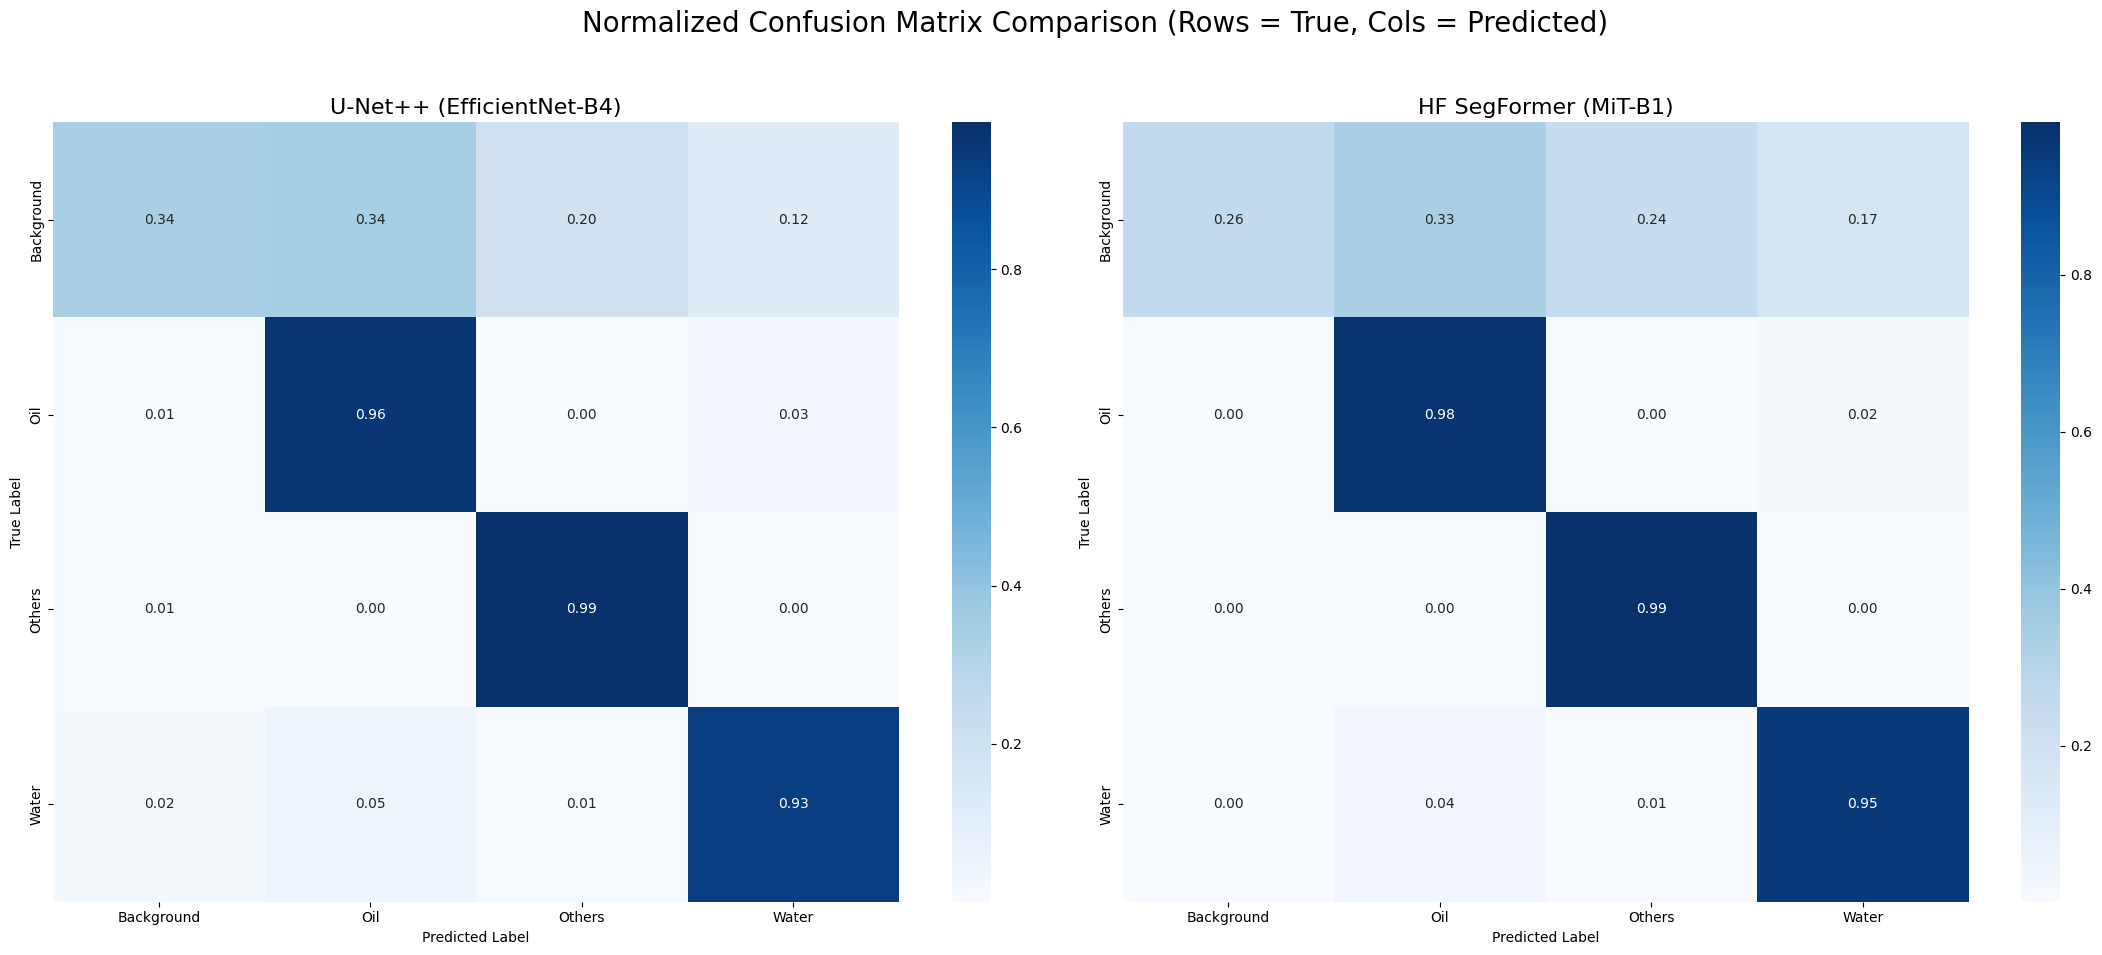

In [ ]:
ORIGINAL_MODEL_PATH = "/content/drive/MyDrive/AI/best_unetpp_effb4.pth"
NEW_MODEL_PATH = "/content/drive/MyDrive/AI/best_hf_segformer_b1.pth"

print("--- 1. Evaluating Original Model (U-Net++ / EffNet-B4) ---")
model_unet_effnet = smp.UnetPlusPlus("timm-efficientnet-b4", encoder_weights=None, in_channels=3, classes=4).to(device)
model_unet_effnet.load_state_dict(torch.load(ORIGINAL_MODEL_PATH, map_location=device))
results_effnet, cm_effnet = run_full_evaluation(model_unet_effnet, "U-Net++ (EffNet-B4)")


print("\n--- 2. Evaluating New Model (HF SegFormer-B1) ---")
model_segformer_hf.load_state_dict(torch.load(NEW_MODEL_PATH, map_location=device))
results_segformer, cm_segformer = run_full_evaluation_hf(model_segformer_hf, "HF SegFormer (MiT-B1)")


print("\n\n--- Final Metrics Comparison (IoU) ---")
comparison_df = pd.DataFrame([results_effnet, results_segformer])
comparison_df = comparison_df.set_index('Model')
print(comparison_df.to_string(float_format="%.4f"))


print("\n\n--- Final Metrics Comparison (Confusion Matrices) ---")
fig, axes = plt.subplots(1, 2, figsize=(22, 10))
fig.suptitle('Normalized Confusion Matrix Comparison (Rows = True, Cols = Predicted)', fontsize=20)

sns.heatmap(cm_effnet, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title("U-Net++ (EfficientNet-B4)", fontsize=16)
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(cm_segformer, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title("HF SegFormer (MiT-B1)", fontsize=16)
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

--- Showing 3 predictions from the HF SegFormer model ---


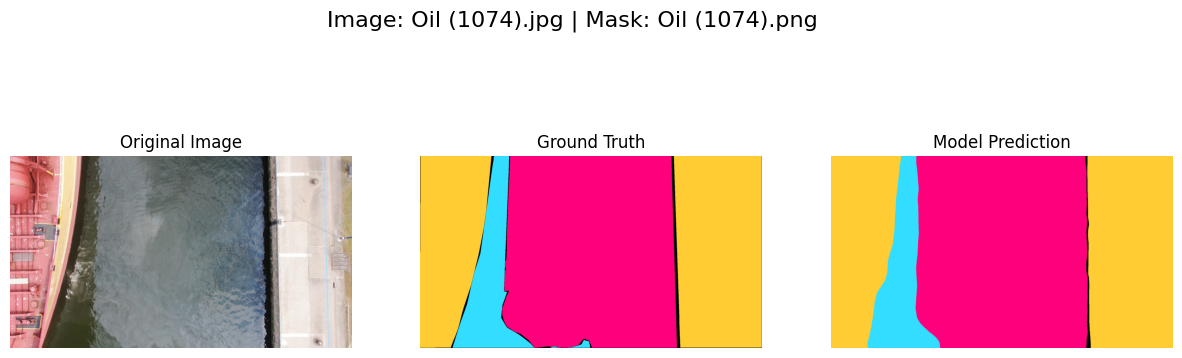

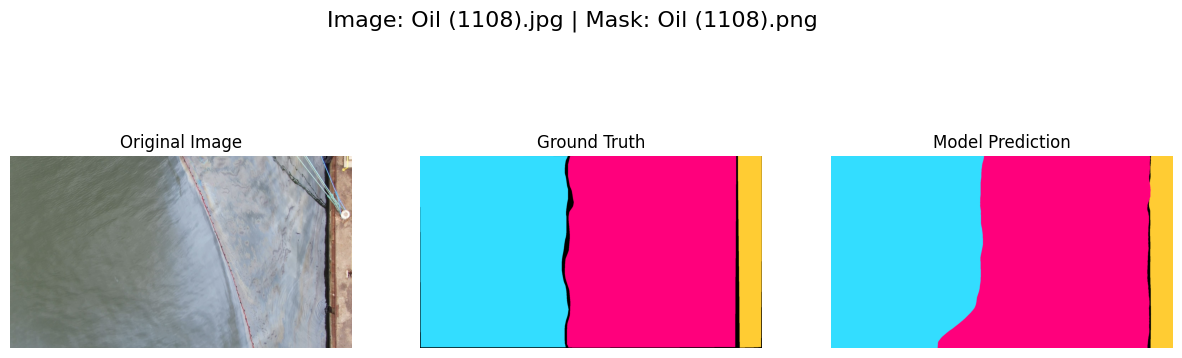

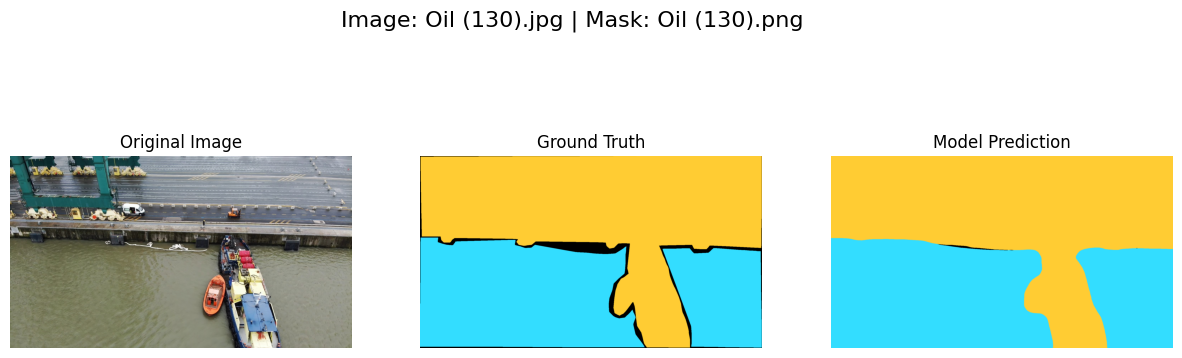

In [ ]:
import random
import cv2
from PIL import Image
import torch.nn.functional as F
import matplotlib.pyplot as plt


HF_SAVE_PATH = "/content/drive/MyDrive/AI/best_hf_segformer_b1.pth"
model_segformer_hf.load_state_dict(torch.load(HF_SAVE_PATH, map_location=device))
model_segformer_hf.eval()

print("--- Showing 3 predictions from the HF SegFormer model ---")

val_img_dir = "val/images"
val_mask_dir = "val/masks"


val_images = sorted(os.listdir(val_img_dir))
val_masks = sorted(os.listdir(val_mask_dir))

indices = random.sample(range(len(val_images)), 3)

with torch.no_grad():
    for i in indices:

        img_name = val_images[i]
        mask_name = val_masks[i]

        img_path = os.path.join(val_img_dir, img_name)
        mask_path = os.path.join(val_mask_dir, mask_name)

        pil_img = Image.open(img_path).convert("RGB")
        display_img = np.array(pil_img)


        mask_bgr = cv2.imread(mask_path)


        if mask_bgr is None:
            print(f"Error: Could not read mask file {mask_path}")
            continue

        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
        ground_truth_mask = mask_to_class(mask_rgb)


        inputs = image_processor(images=pil_img, return_tensors="pt").to(device)
        outputs = model_segformer_hf(**inputs)
        logits = outputs.logits


        upsampled_logits = F.interpolate(
            logits,
            size=ground_truth_mask.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        pred_class_mask = torch.argmax(upsampled_logits, dim=1).cpu().squeeze().numpy()


        plt.figure(figsize=(15, 5))
        plt.suptitle(f"Image: {img_name} | Mask: {mask_name}", fontsize=16)

        plt.subplot(1, 3, 1)
        plt.imshow(display_img)
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(class_to_color(ground_truth_mask))
        plt.title("Ground Truth")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(class_to_color(pred_class_mask))
        plt.title("Model Prediction")
        plt.axis("off")

        plt.show()



--- Showing 3 predictions from the HF SegFormer model ---


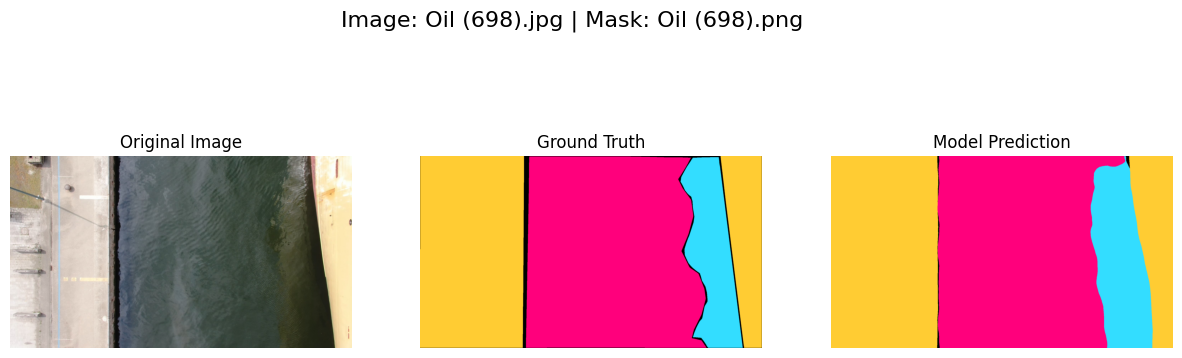

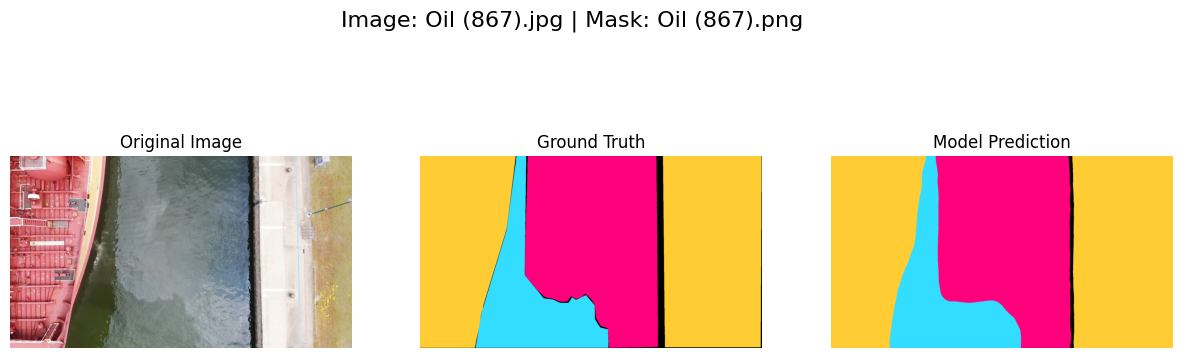

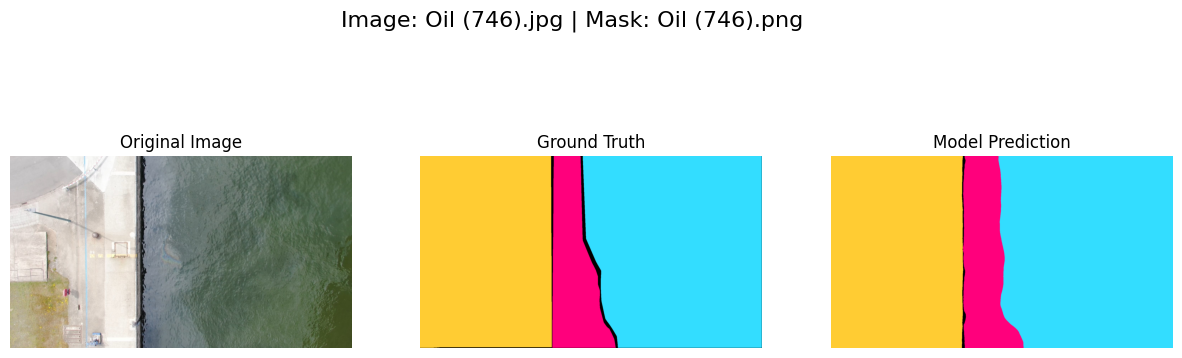

In [ ]:
import random
import cv2
from PIL import Image
import torch.nn.functional as F
import matplotlib.pyplot as plt


HF_SAVE_PATH = "/content/drive/MyDrive/AI/best_hf_segformer_b1.pth"
model_segformer_hf.load_state_dict(torch.load(HF_SAVE_PATH, map_location=device))
model_segformer_hf.eval()

print("--- Showing 3 predictions from the HF SegFormer model ---")

val_img_dir = "train/images"
val_mask_dir = "train/masks"


val_images = sorted(os.listdir(val_img_dir))
val_masks = sorted(os.listdir(val_mask_dir))



indices = random.sample(range(len(val_images)), 3)

with torch.no_grad():
    for i in indices:

        img_name = val_images[i]
        mask_name = val_masks[i]

        img_path = os.path.join(val_img_dir, img_name)
        mask_path = os.path.join(val_mask_dir, mask_name)

        pil_img = Image.open(img_path).convert("RGB")
        display_img = np.array(pil_img)


        mask_bgr = cv2.imread(mask_path)


        if mask_bgr is None:
            print(f"Error: Could not read mask file {mask_path}")
            continue

        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
        ground_truth_mask = mask_to_class(mask_rgb)

        inputs = image_processor(images=pil_img, return_tensors="pt").to(device)
        outputs = model_segformer_hf(**inputs)
        logits = outputs.logits

        upsampled_logits = F.interpolate(
            logits,
            size=ground_truth_mask.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        pred_class_mask = torch.argmax(upsampled_logits, dim=1).cpu().squeeze().numpy()


        plt.figure(figsize=(15, 5))
        plt.suptitle(f"Image: {img_name} | Mask: {mask_name}", fontsize=16)

        plt.subplot(1, 3, 1)
        plt.imshow(display_img)
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(class_to_color(ground_truth_mask))
        plt.title("Ground Truth")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(class_to_color(pred_class_mask))
        plt.title("Model Prediction")
        plt.axis("off")

        plt.show()



--- Showing 3 predictions from the HF SegFormer model ---


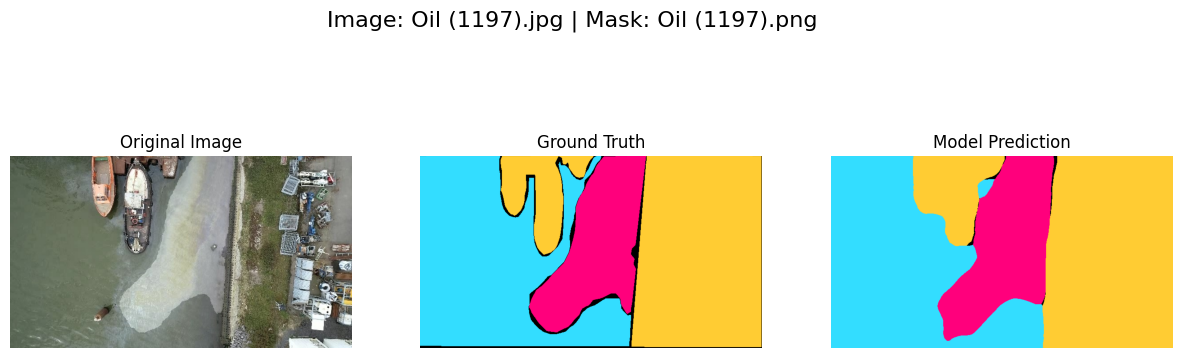

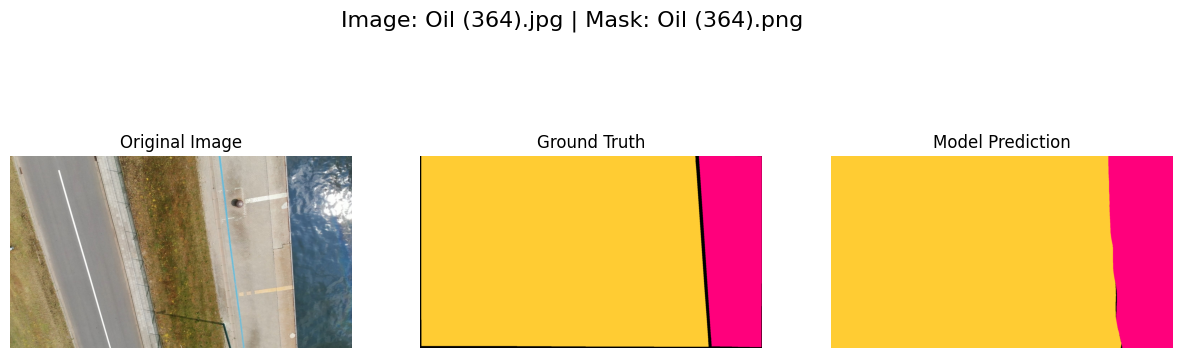

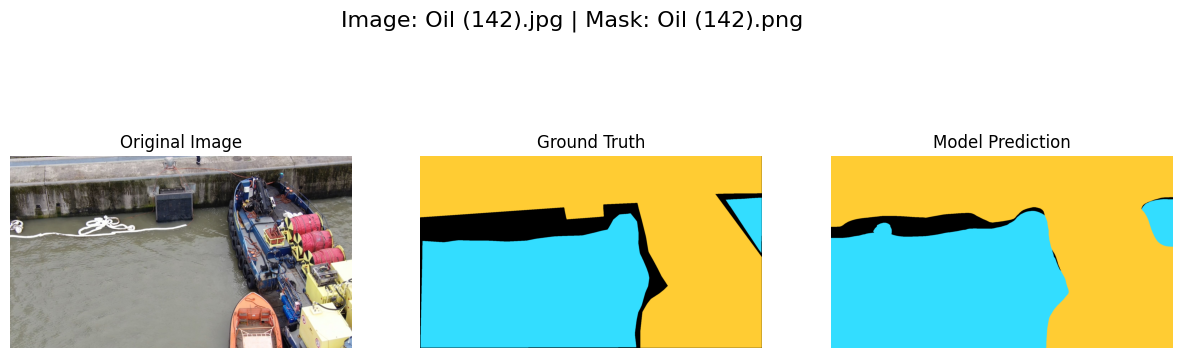

In [ ]:
import random
import cv2
from PIL import Image
import torch.nn.functional as F
import matplotlib.pyplot as plt


HF_SAVE_PATH = "/content/drive/MyDrive/AI/best_hf_segformer_b1.pth"
model_segformer_hf.load_state_dict(torch.load(HF_SAVE_PATH, map_location=device))
model_segformer_hf.eval()

print("--- Showing 3 predictions from the HF SegFormer model ---")

val_img_dir = "test/images"
val_mask_dir = "test/masks"


val_images = sorted(os.listdir(val_img_dir))
val_masks = sorted(os.listdir(val_mask_dir))



indices = random.sample(range(len(val_images)), 3)

with torch.no_grad():
    for i in indices:

        img_name = val_images[i]
        mask_name = val_masks[i]



        img_path = os.path.join(val_img_dir, img_name)
        mask_path = os.path.join(val_mask_dir, mask_name)


        pil_img = Image.open(img_path).convert("RGB")
        display_img = np.array(pil_img)


        mask_bgr = cv2.imread(mask_path)


        if mask_bgr is None:
            print(f"Error: Could not read mask file {mask_path}")
            continue

        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
        ground_truth_mask = mask_to_class(mask_rgb)


        inputs = image_processor(images=pil_img, return_tensors="pt").to(device)
        outputs = model_segformer_hf(**inputs)
        logits = outputs.logits


        upsampled_logits = F.interpolate(
            logits,
            size=ground_truth_mask.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        pred_class_mask = torch.argmax(upsampled_logits, dim=1).cpu().squeeze().numpy()


        plt.figure(figsize=(15, 5))
        plt.suptitle(f"Image: {img_name} | Mask: {mask_name}", fontsize=16)

        plt.subplot(1, 3, 1)
        plt.imshow(display_img)
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(class_to_color(ground_truth_mask))
        plt.title("Ground Truth")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(class_to_color(pred_class_mask))
        plt.title("Model Prediction")
        plt.axis("off")

        plt.show()



In [ ]:
import torchmetrics
from torchmetrics.classification import (
    MulticlassJaccardIndex,
    MulticlassConfusionMatrix,
    MulticlassPrecision,
    MulticlassRecall,
    MulticlassF1Score
)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

CLASS_NAMES = ['Background', 'Oil', 'Others', 'Water']
NUM_CLASSES = len(CLASS_NAMES)

def run_full_evaluation_v2(model_to_eval, model_name):
    print(f"--- Running full evaluation for {model_name} ---")

    metrics = torchmetrics.MetricCollection({
        'IoU (macro)': MulticlassJaccardIndex(num_classes=NUM_CLASSES, average='macro'),
        'F1 (macro)': MulticlassF1Score(num_classes=NUM_CLASSES, average='macro'),
        'Recall (macro)': MulticlassRecall(num_classes=NUM_CLASSES, average='macro'),
        'Precision (macro)': MulticlassPrecision(num_classes=NUM_CLASSES, average='macro'),

        'IoU (per-class)': MulticlassJaccardIndex(num_classes=NUM_CLASSES, average=None),
        'F1 (per-class)': MulticlassF1Score(num_classes=NUM_CLASSES, average=None)
    }).to(device)

    model_to_eval.eval()
    with torch.no_grad():
        for imgs, masks in tqdm(val_loader, desc=f"Evaluating {model_name}"):
            imgs, masks = imgs.to(device), masks.to(device)
            preds = model_to_eval(imgs)
            preds_class = torch.argmax(preds, dim=1)
            metrics.update(preds_class, masks)

    computed_metrics = metrics.compute()
    metrics.reset()

    results = {'Model': model_name}
    for key, value in computed_metrics.items():
        if 'per-class' in key:
            for i, class_name in enumerate(CLASS_NAMES):
                results[f'{class_name} {key.split(" ")[0]}'] = value[i].item()
        else:
            results[key] = value.item()

    print(f"--- Evaluation for {model_name} complete ---")
    return results

def run_full_evaluation_hf_v2(model_to_eval, model_name):
    print(f"--- Running full HF evaluation for {model_name} ---")

    metrics = torchmetrics.MetricCollection({
        'IoU (macro)': MulticlassJaccardIndex(num_classes=NUM_CLASSES, average='macro'),
        'F1 (macro)': MulticlassF1Score(num_classes=NUM_CLASSES, average='macro'),
        'Recall (macro)': MulticlassRecall(num_classes=NUM_CLASSES, average='macro'),
        'Precision (macro)': MulticlassPrecision(num_classes=NUM_CLASSES, average='macro'),

        'IoU (per-class)': MulticlassJaccardIndex(num_classes=NUM_CLASSES, average=None),
        'F1 (per-class)': MulticlassF1Score(num_classes=NUM_CLASSES, average=None)
    }).to(device)

    model_to_eval.eval()
    with torch.no_grad():
        for batch in tqdm(hf_val_loader, desc=f"Evaluating {model_name}"):
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch["labels"]

            outputs = model_to_eval(pixel_values=batch["pixel_values"])
            logits = outputs.logits

            upsampled_logits = F.interpolate(
                logits,
                size=labels.shape[-2:],
                mode="bilinear",
                align_corners=False
            )
            preds_class = torch.argmax(upsampled_logits, dim=1)
            metrics.update(preds_class, labels)

    computed_metrics = metrics.compute()
    metrics.reset()

    results = {'Model': model_name}
    for key, value in computed_metrics.items():
        if 'per-class' in key:
            for i, class_name in enumerate(CLASS_NAMES):
                results[f'{class_name} {key.split(" ")[0]}'] = value[i].item()
        else:
            results[key] = value.item()

    print(f"--- Evaluation for {model_name} complete ---")
    return results

In [ ]:

results_effnet_v2 = run_full_evaluation_v2(model_unet_effnet, "U-Net++ (EffNet-B4)")

results_segformer_v2 = run_full_evaluation_hf_v2(model_segformer_hf, "HF SegFormer (MiT-B1)")


df_v2 = pd.DataFrame([results_effnet_v2, results_segformer_v2])
df_v2 = df_v2.set_index('Model')


print("\n\n--- Overall Metrics Comparison (Macro Averages) ---")
print(df_v2[['IoU (macro)', 'F1 (macro)', 'Precision (macro)', 'Recall (macro)']].to_string(float_format="%.4f"))

print("\n\n--- Per-Class IoU Comparison ---")
print(df_v2[['Background IoU', 'Oil IoU', 'Others IoU', 'Water IoU']].to_string(float_format="%.4f"))

print("\n\n--- Per-Class F1-Score (Dice) Comparison ---")
print(df_v2[['Background F1', 'Oil F1', 'Others F1', 'Water F1']].to_string(float_format="%.4f"))

--- Running full evaluation for U-Net++ (EffNet-B4) ---


Evaluating U-Net++ (EffNet-B4): 100%|██████████| 13/13 [01:11<00:00,  5.47s/it]


--- Evaluation for U-Net++ (EffNet-B4) complete ---
--- Running full HF evaluation for HF SegFormer (MiT-B1) ---


Evaluating HF SegFormer (MiT-B1): 100%|██████████| 13/13 [01:17<00:00,  5.95s/it]

--- Evaluation for HF SegFormer (MiT-B1) complete ---


--- Overall Metrics Comparison (Macro Averages) ---
                       IoU (macro)  F1 (macro)  Precision (macro)  Recall (macro)
Model                                                                            
U-Net++ (EffNet-B4)         0.7482      0.8182             0.8447          0.8035
HF SegFormer (MiT-B1)       0.7579      0.8215             0.9223          0.7970


--- Per-Class IoU Comparison ---
                       Background IoU  Oil IoU  Others IoU  Water IoU
Model                                                                
U-Net++ (EffNet-B4)            0.2614   0.9007      0.9576     0.8731
HF SegFormer (MiT-B1)          0.2500   0.9211      0.9624     0.8979


--- Per-Class F1-Score (Dice) Comparison ---
                       Background F1  Oil F1  Others F1  Water F1
Model                                                            
U-Net++ (EffNet-B4)           0.4145  0.9477     0.9783    0.9323
HF S